# Task4 — Compound corruption: authorized full training

**Run All: ใช้ folds1–2 เดิม → ฝึก folds3–5 → ประเมินครบ5 folds → final audit → full-data refit6 epochs.** เก็บ checkpoint ทุก epoch. ผล strict gate เดิมยังรายงานตามจริง; ฝึกต่อได้รับอนุญาตจากผู้ใช้ ไม่ใช่การอ้างว่าผ่าน pilot. Export ต้องผ่านเกณฑ์ทั้ง development/audit. แนวคิดมีข้อมูลชี้นำจากภาพตัวอย่างที่ผู้ใช้ส่ง แหล่งที่มายังไม่ยืนยัน. ไม่ใช้ pixels จากภาพตัวอย่างหรือ Test ใน training/validation.

สูตรใหม่: 60% สุ่ม compound corruption 2–3 operations; 40% heavy augmentation เดิม. Weighted CE ภาพเดียว ไม่มี JSD. แนวคิดมาจากภาพตัวอย่างที่ผู้ใช้ส่ง โดยยังไม่ยืนยันแหล่งที่มา; ไม่ใช้ pixels ของภาพตัวอย่างหรือไฟล์ Test ฝึกหรือวัดผล. หากภาพตัวอย่างเป็น Test จริง ต้องเปิดเผยว่าได้รับข้อมูลชี้นำจาก Test และตรวจข้ออนุญาตกับ TA. ไม่อ้างว่าเป็น Test-blind development. เกณฑ์เดิมยังคงอยู่พร้อมเพิ่ม compound gate; ไม่เทียบคะแนนเฉลี่ยข้าม protocol โดยตรง.

## 1. Settings ก่อนเริ่ม

In [20]:
from pathlib import Path
import sys,json,hashlib,csv,gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from dataclasses import asdict
from IPython.display import display
ROOT=next(p for b in (Path.cwd(),*Path.cwd().parents) for p in (b,b/'CPE342-Kaggle') if (p/'Task4/models/image_compound_followup.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from Task4.models import image_compound_followup as training
from Task4.models import image_compound_validation as validation
from Task4.models.image_compound_transforms import TrainingTransform,CONDITIONS,corrupt
from Task4.models.image_audit import make_folds
RUN_MODE='full'                 # user-authorized full CV, audit, then full-data refit
AUTHORIZED_FULL_RUN=True        # execution authorization; never overrides evaluation results
RUN_NAME='compound_supervised_v1'
BATCH_SIZE=16                    # 16 images per forward; one training view
NUM_WORKERS=0
STRESS_PER_CLASS=100
RUN_FINAL_REFIT=True             # only reached in full mode after all gates pass
RUN_EXPORT=True                 # only reads Test after full validation and refit
RAW=ROOT/'Task4/data/raw'
AUDIT=ROOT/'Task4/data/audit/followup_v2'
HEAVY=ROOT/'Task4/models/results/heavy_balance_v1'
LEGACY=ROOT/'Task4/models/results/gpu_followup_v1'
OUT=ROOT/'Task4/models/results'/RUN_NAME
RECIPE='compound_supervised6'
BASE_SUBMISSION=ROOT/'submission/kaggle_t12345_t4_heavy_balance_v1_t5_directional_gap_cut_v1.csv'
BASE_SHA='ea22cd8aa528ee7b63611a6e86b25cfc1c6849ded905bf927e9731b4f873229b'
assert RUN_MODE in ['pilot','confirm_fold2','full']
torch.set_num_threads(4)
print('Device:',training.get_device(),'| mode:',RUN_MODE,'| output:',OUT)
if training.get_device().type=='cpu':raise RuntimeError('เปิด kernel ที่รองรับ MPS/CUDA ก่อนฝึกงานเต็ม')


Device: mps | mode: full | output: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/compound_supervised_v1


## 2. Verify Train, folds, checkpoints & lock the recipe

โหลดเฉพาะ train.csv และ Train audit. ตรวจ Train image hashes เพื่อให้ baseline cache ยังตรงกับข้อมูลเดิม. แผน augmentation, sampling และ pass criteria บันทึกก่อนฝึก. เปลี่ยน hyperparameters/source ให้ใช้ RUN_NAME ใหม่; การสลับ pilot → full ใช้ run เดิมได้.

In [21]:
train=pd.read_csv(RAW/'train.csv')
groups=pd.read_parquet(AUDIT/'train_groups.parquet')
assert len(train)==len(groups)==31546
assert all(np.array_equal(train[c],groups[c]) for c in ['id','file_name','label'])
assert train.label.notna().all() and set(train.label)==set(range(5))
assert train.id.is_unique and train.file_name.is_unique
metadata=pd.read_parquet(AUDIT/'images.parquet',filters=[('split','=','train')])
metadata=metadata.loc[metadata.split.eq('train')].set_index('id').loc[train.id]
assert metadata.file_name.tolist()==train.file_name.tolist()
inventory=hashlib.sha256()
for row in metadata.itertuples():
    image_path=RAW/'train'/row.file_name
    assert Path(row.file_name).name==row.file_name
    digest=validation.sha(image_path)
    assert digest==row.sha256, f'Train image changed: {row.file_name}'
    inventory.update(f'{row.file_name}/{digest}'.encode())
folds=make_folds(groups,mode='near',n_splits=5,seed=42)
fold_hash=hashlib.sha256(b''.join(v.astype('int64').tobytes() for _,v in folds)).hexdigest()
assert fold_hash==json.loads((LEGACY/'settings.json').read_text())['fold_hash']
old_settings=json.loads((HEAVY/'settings.json').read_text())
assert fold_hash==old_settings['fold_hash']
for filename,digest in old_settings['sources'].items():assert validation.sha(ROOT/'Task4/models'/filename)==digest
source_hashes={name:validation.sha(ROOT/'Task4/models'/name) for name in ['image_compound_followup.py','image_compound_transforms.py','image_compound_validation.py','image_followup.py','image_training.py','image_heavy_augmentation.py','image_mixed_consistency_transforms.py']}
checkpoint_hashes={}
for k,(fit,valid) in enumerate(folds,1):
    assert not np.intersect1d(fit,valid).size
    for parent,name in [(HEAVY,'heavy_weighted18'),(HEAVY,'heavy_sampler18'),(LEGACY,'resnet18_cosine18')]:
        path=parent/name/f'fold{k}'/'model.pt'
        assert path.exists(),f'Missing baseline checkpoint: {path}'
        signature=json.loads((path.parent/'signature.json').read_text())
        assert signature['data_signature']==validation.sha_frame(groups.iloc[fit])
        frame=pd.read_parquet(path.parent/'oof.parquet')
        assert np.array_equal(frame.row_index,valid) and frame.id.tolist()==groups.iloc[valid].id.tolist()
        assert np.array_equal(frame.true,groups.iloc[valid].label.astype(int))
        checkpoint_hashes[f'{name}/fold{k}']=validation.sha(path)
for name,run,recipe in [('mixed','mixed_consistency_v1','mixed_consistency6'),('noise','noise_supervised_v1','noise_supervised6')]:
    path=ROOT/'Task4/models/results'/run/recipe/'fold1/model.pt'
    assert path.exists()
    checkpoint_hashes[name+'/fold1']=validation.sha(path)
settings={'recipe':asdict(training.RECIPES[RECIPE]),'sources':source_hashes,'checkpoint_hashes':checkpoint_hashes,
 'fold_hash':fold_hash,'train_manifest_sha256':validation.sha(RAW/'train.csv'),'train_inventory':inventory.hexdigest(),
 'rules':validation.RULES,'conditions':CONDITIONS,'stress_per_class':STRESS_PER_CLASS,'batch_size':BATCH_SIZE,'workers':NUM_WORKERS,
 'torch':str(torch.__version__),'device':str(training.get_device()),'base_submission_sha256':BASE_SHA}
settings=json.loads(json.dumps(settings))
OUT.mkdir(parents=True,exist_ok=True)
if (OUT/'settings.json').exists():assert json.loads((OUT/'settings.json').read_text())==settings,'Configuration changed: choose a new RUN_NAME'
else:
    assert not any(OUT.iterdir()),'Nonempty output without settings'
    validation.write_json(OUT/'settings.json',settings)
display(train.label.value_counts().sort_index().rename('train_count'))
display(pd.DataFrame([{'condition':k,'phase':v[0],'type':v[1],'strength':v[2]} for k,v in CONDITIONS.items()]))
print('Matched Train checkpoints verified. Test has not been opened.')


label
0    12429
1     4407
2     5596
3     5926
4     3188
Name: train_count, dtype: int64

,condition,phase,type,strength
0,gaussian_1,development,gaussian,0.08
1,gaussian_2,development,gaussian,0.16
2,speckle_1,development,speckle,0.15
3,speckle_2,development,speckle,0.30
4,blur_1,development,blur,1.00
5,blur_2,development,blur,2.00
6,jpeg_1,development,jpeg,40.00
7,jpeg_2,development,jpeg,20.00
8,dark_1,development,dark,0.60
9,dark_2,development,dark,0.30


Matched Train checkpoints verified. Test has not been opened.


## 3. Compound training preview

60%: สุ่ม exposure หรือ gamma หรือ RGB channel gains แล้วเพิ่ม Gaussian/speckle และอาจหมุนภาพ; 40%: heavy augmentation เดิม. ไม่ซ้อน heavy ทั้งสูตรบน compound. ห้ามปรับสูตรตาม final audit. Training ใช้หนึ่งภาพต่อรายการ; preview แสดงสาม random draws. ชุด development มี single10 + compound6; audit มี single4 + compound2 ที่ไม่ได้ใช้ผสมในการฝึก. Synthetic validation ไม่รับประกันคะแนน Kaggle.

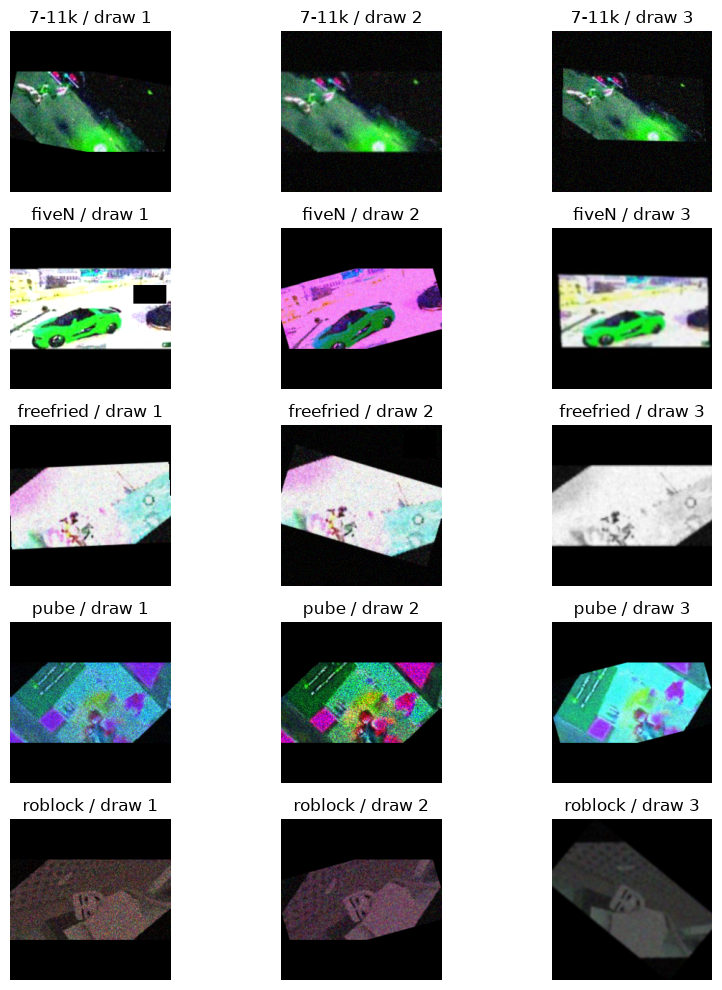

In [22]:
training.seed_everything(123)
fig,axes=plt.subplots(5,3,figsize=(9,10));augment=TrainingTransform()
for label in range(5):
    row=train.loc[train.label.eq(label)].iloc[0]
    with Image.open(RAW/'train'/row.file_name) as f:image=f.convert('RGB')
    for j in range(3):
        t=augment(image)[0]
        rgb=(t*torch.tensor(training.STD)[:,None,None]+torch.tensor(training.MEAN)[:,None,None]).clamp(0,1)
        axes[label,j].imshow(rgb.permute(1,2,0));axes[label,j].set_title(f'{training.CLASS_NAMES[label]} / draw {j+1}');axes[label,j].axis('off')
plt.tight_layout();fig.savefig(OUT/'compound_preview.png',dpi=120);plt.show()


## 4. Pilot fold1 — train แล้ว paired validation

ทั้งสอง references และ candidate ใช้ held-out rows เดียวกัน. Original OOF ใช้ทุกภาพใน fold; stress ใช้ 100 ภาพต่อ class ด้วย seed คงที่. ทุกโมเดลเห็น corruption pixels และ 5-view TTA เหมือนกัน. แบ่ง development 16 conditions กับ final audit 6 conditions. ไม่ใช่สัดส่วน corruption จริงของการแข่งขัน. Stress cache อาจใช้เวลา แต่กลับมาใช้ซ้ำได้.

In [23]:
if RUN_MODE in ['confirm_fold2','full']:
    # Reuse completed pilot evidence; never rewrite its failed decision.
    assert (OUT/'pilot_decision.json').exists() and (OUT/'comparison_fold1_development.parquet').exists()
    pilot_scores=pd.read_parquet(OUT/'comparison_fold1_development.parquet')
    pilot=json.loads((OUT/'pilot_decision.json').read_text())
    assert pilot==validation.decision(pilot_scores,full=False), 'Pilot evidence changed'
else:
    frame=training.run_fold(RAW,groups,folds,RECIPE,1,OUT,BATCH_SIZE,NUM_WORKERS,
        init_path=HEAVY/'heavy_weighted18/fold1/model.pt')
    pilot_scores=validation.fold_comparison(ROOT,RAW,groups,folds,OUT,1,frame,per_class=STRESS_PER_CLASS)
    pilot=validation.decision(pilot_scores,full=False)
    validation.write_json(OUT/'pilot_decision.json',pilot)
report=pilot_scores.copy()
report['suite']=np.where(report.condition.str.startswith('compound_'),'compound',report.phase.map({'original':'original','development':'single'}))
display(report.groupby(['suite','procedure']).macro_F1.mean().unstack())
display(pilot)
if not pilot['passed']:print('Pilot เดิมไม่ผ่านตามเกณฑ์; full run ได้รับอนุญาตให้ฝึกต่อแยกจากผลประเมิน')


procedure,compound_weighted_plus_sampler__tta,heavy_equal_ensemble__tta,mixed_reference__tta,noise_reference__tta,resnet18_cosine18__tta
suite,,,,,
compound,0.929587,0.912299,0.917413,0.917594,0.868516
original,0.981367,0.979939,0.982512,0.982071,0.973701
single,0.975196,0.971631,0.973061,0.973229,0.959124


{'passed': False,
 'full': False,
 'phase': 'development',
 'checks': {'heavy_equal_ensemble__tta/stress_mean': True,
  'heavy_equal_ensemble__tta/compound_mean': True,
  'heavy_equal_ensemble__tta/single_mean': False,
  'heavy_equal_ensemble__tta/worst_condition': True,
  'heavy_equal_ensemble__tta/original_mean': True,
  'heavy_equal_ensemble__tta/per_class': True,
  'heavy_equal_ensemble__tta/fold_wins': True,
  'resnet18_cosine18__tta/stress_mean': True,
  'resnet18_cosine18__tta/compound_mean': True,
  'resnet18_cosine18__tta/single_mean': True,
  'resnet18_cosine18__tta/worst_condition': True,
  'resnet18_cosine18__tta/original_mean': True,
  'resnet18_cosine18__tta/per_class': True,
  'resnet18_cosine18__tta/fold_wins': True},
 'details': {'heavy_equal_ensemble__tta': {'mean_stress_gain': 0.008711137489017202,
   'worst_condition_gain': -0.002052361382679835,
   'stress_fold_wins': 1,
   'per_class_deltas': {'F1_7-11k': 0.0011932022806218079,
    'F1_fiveN': 0.0,
    'F1_freefri

Pilot เดิมไม่ผ่านตามเกณฑ์; full run ได้รับอนุญาตให้ฝึกต่อแยกจากผลประเมิน


## 4.1. Fold 2 confirmation — independently requested follow-up

โหมด `confirm_fold2` ใช้สูตรเดิมฝึกเฉพาะ fold2 6 epochs จาก heavy checkpoint ของ fold2. เก็บ pilot fold1 ว่าไม่ผ่านตามเดิม ไม่ลด threshold. เก็บรายงาน fold2 แยก และแสดงผลต่างของแต่ละ suite ทั้งสอง folds. เกณฑ์ strict เดิมใช้ประเมิน fold2 เช่นกัน; ผลนี้ไม่อนุมัติ full training อัตโนมัติ. Final audit, full refit และ Test export ยังไม่เปิด. นี่เป็น exploratory replication หลังเห็น fold1 ไม่ใช่ independent holdout ของกระบวนการพัฒนาทั้งหมด.

In [24]:
confirmation_scores=None
if RUN_MODE=='confirm_fold2':
    protocol={'mode':'confirm_fold2','fold':2,'recipe':asdict(training.RECIPES[RECIPE]),
              'rules':validation.RULES,'source_hashes':source_hashes,
              'pilot_decision_sha256':validation.sha(OUT/'pilot_decision.json'),
              'pilot_scores_sha256':validation.sha(OUT/'comparison_fold1_development.parquet'),
              'automatic_full_training':False,'test_access':False}
    protocol=json.loads(json.dumps(protocol))
    protocol_path=OUT/'fold2_confirmation_protocol.json'
    if protocol_path.exists():assert json.loads(protocol_path.read_text())==protocol
    else:validation.write_json(protocol_path,protocol)
    frame2=training.run_fold(RAW,groups,folds,RECIPE,2,OUT,BATCH_SIZE,NUM_WORKERS,
        init_path=HEAVY/'heavy_weighted18/fold2/model.pt')
    confirmation_scores=validation.fold_comparison(ROOT,RAW,groups,folds,OUT,2,frame2,per_class=STRESS_PER_CLASS)
    # Existing decision() accepts one pilot fold numbered 1. Renumber a temporary
    # scoring copy only; stored OOF, predictions, splits and reports retain fold2.
    scoring_copy=confirmation_scores.copy()
    assert set(scoring_copy.fold)=={2}
    scoring_copy['fold']=1
    confirmation=validation.decision(scoring_copy,full=False)
    confirmation.update(evaluated_fold=2,purpose='exploratory replication; unchanged strict rules',
                        automatic_full_training=False)
    validation.write_json(OUT/'fold2_confirmation_decision.json',confirmation)
    report2=pd.concat([pilot_scores,confirmation_scores],ignore_index=True)
    report2['suite']=np.where(report2.condition.str.startswith('compound_'),'compound',
                             report2.phase.map({'original':'original','development':'single'}))
    summary=report2.groupby(['fold','suite','procedure']).macro_F1.mean().unstack()
    summary.to_parquet(OUT/'fold2_confirmation_summary.parquet')
    display(summary)
    display(summary.subtract(summary[validation.PRIMARY_BASE],axis=0))
    display(confirmation)
    print('Fold2 confirmation complete. ไม่ฝึก folds3–5 ไม่ทำ audit/refit/export; ตรวจผลก่อนตัดสินใจต่อ')


## 5. Authorized full 5-fold training

ผู้ใช้อนุญาตให้ฝึกต่อหลังเห็นผลสอง folds. ใช้ checkpoint/cache ที่เสร็จแล้ว และฝึก folds3–5 ด้วยสูตรเดิม. ผลเกณฑ์ strict บันทึกตามจริง แม้ไม่ผ่านก็ทำ final audit และ full-data refit เพื่อเก็บโมเดลตามคำขอ; ไม่เปลี่ยน false เป็น true. ไม่อนุญาตให้ปรับสูตรตาม audit.

In [25]:
development_pass=False
development_scores=pd.concat([pilot_scores,confirmation_scores],ignore_index=True) if confirmation_scores is not None else pilot_scores.copy()
if RUN_MODE=='full' and AUTHORIZED_FULL_RUN:
    full_protocol={'mode':'authorized_full','recipe':asdict(training.RECIPES[RECIPE]),
        'source_hashes':source_hashes,'strict_rules':validation.RULES,
        'pilot_sha256':validation.sha(OUT/'pilot_decision.json'),
        'fold2_sha256':validation.sha(OUT/'fold2_confirmation_decision.json'),
        'execution':'complete CV and audit, then full refit even if strict screening fails',
        'export_requires_strict_pass':True}
    full_protocol=json.loads(json.dumps(full_protocol))
    protocol_path=OUT/'authorized_full_protocol.json'
    if protocol_path.exists():assert json.loads(protocol_path.read_text())==full_protocol
    else:validation.write_json(protocol_path,full_protocol)
    parts=[pilot_scores]
    for k in range(2,6):
        frame=training.run_fold(RAW,groups,folds,RECIPE,k,OUT,BATCH_SIZE,NUM_WORKERS,
            init_path=HEAVY/'heavy_weighted18'/f'fold{k}'/'model.pt')
        parts.append(validation.fold_comparison(ROOT,RAW,groups,folds,OUT,k,frame,per_class=STRESS_PER_CLASS))
    development_scores=pd.concat(parts,ignore_index=True)
    development_scores.to_parquet(OUT/'development_scores.parquet',index=False)
    development=validation.decision(development_scores,full=True)
    validation.write_json(OUT/'development_decision.json',development)
    development_pass=development['passed']
    display(development);display(development_scores.groupby(['phase','procedure']).macro_F1.mean().unstack())
else:print('ไม่ได้เลือก authorized full run')


fold3 epoch 1 / 6 loss 0.0874 seconds 143.6
fold3 epoch 2 / 6 loss 0.07953 seconds 143.2
fold3 epoch 3 / 6 loss 0.07288 seconds 145.6
fold3 epoch 4 / 6 loss 0.06633 seconds 143.5
fold3 epoch 5 / 6 loss 0.05979 seconds 143.2
fold3 epoch 6 / 6 loss 0.05276 seconds 143.8
stress candidate gaussian_1
stress candidate gaussian_2
stress candidate speckle_1
stress candidate speckle_2
stress candidate blur_1
stress candidate blur_2
stress candidate jpeg_1
stress candidate jpeg_2
stress candidate dark_1
stress candidate dark_2
stress candidate compound_dark_noise
stress candidate compound_color_noise
stress candidate compound_rotation_dark
stress candidate compound_bright_color
stress candidate compound_dark_color_noise
stress candidate compound_rotation_color_noise
stress weighted gaussian_1
stress weighted gaussian_2
stress weighted speckle_1
stress weighted speckle_2
stress weighted blur_1
stress weighted blur_2
stress weighted jpeg_1
stress weighted jpeg_2
stress weighted dark_1
stress weigh

{'passed': False,
 'full': True,
 'phase': 'development',
 'checks': {'heavy_equal_ensemble__tta/stress_mean': True,
  'heavy_equal_ensemble__tta/compound_mean': True,
  'heavy_equal_ensemble__tta/single_mean': False,
  'heavy_equal_ensemble__tta/worst_condition': True,
  'heavy_equal_ensemble__tta/original_mean': True,
  'heavy_equal_ensemble__tta/per_class': True,
  'heavy_equal_ensemble__tta/fold_wins': True,
  'resnet18_cosine18__tta/stress_mean': True,
  'resnet18_cosine18__tta/compound_mean': True,
  'resnet18_cosine18__tta/single_mean': True,
  'resnet18_cosine18__tta/worst_condition': True,
  'resnet18_cosine18__tta/original_mean': True,
  'resnet18_cosine18__tta/per_class': True,
  'resnet18_cosine18__tta/fold_wins': True},
 'details': {'heavy_equal_ensemble__tta': {'mean_stress_gain': 0.010117388323853838,
   'worst_condition_gain': -0.0015623038778488142,
   'stress_fold_wins': 5,
   'per_class_deltas': {'F1_7-11k': 0.00027757207869338885,
    'F1_fiveN': 0.00010856960504179

procedure,compound_weighted_plus_sampler__tta,heavy_equal_ensemble__tta,mixed_reference__tta,noise_reference__tta,resnet18_cosine18__tta
phase,,,,,
development,0.957375,0.947258,0.952193,0.952366,0.923887
original,0.980847,0.980339,0.982512,0.982071,0.975511


## 6. Final audit หลัง development ครบ5 folds

รันสูตรเดิมบน audit ทุก fold ตามการอนุญาตฝึกครบ. บันทึกผลโดยไม่แก้ thresholds หรือสูตรตาม audit. READY สำหรับ export ต้องผ่านทั้ง development strict และ audit; full-data refit เป็นการทำงานที่อนุญาตแยกจาก READY.

In [26]:
READY=False
FULL_EVALUATED=False
audit_scores=None
if RUN_MODE=='full' and AUTHORIZED_FULL_RUN and set(development_scores.fold)==set(range(1,6)):
    parts=[]
    for k in range(1,6):
        frame=pd.read_parquet(OUT/RECIPE/f'fold{k}'/'oof.parquet')
        parts.append(validation.fold_comparison(ROOT,RAW,groups,folds,OUT,k,frame,phase='audit',per_class=STRESS_PER_CLASS))
    audit_scores=pd.concat(parts,ignore_index=True)
    audit_scores.to_parquet(OUT/'audit_scores.parquet',index=False)
    audit=validation.decision(audit_scores,full=True,phase='audit')
    validation.write_json(OUT/'audit_decision.json',audit)
    FULL_EVALUATED=True
    READY=bool(development_pass and audit['passed']);display(audit)
    validation.write_json(OUT/'selection.json',{'ready_for_refit':FULL_EVALUATED,'strict_ready_for_export':READY,'development_pass':development_pass,'audit_pass':audit['passed'],'authorized_full_refit':True,'procedure':validation.NAME,
        'references':[validation.PRIMARY_BASE,validation.LEGACY_BASE],
        'note':'Synthetic robustness screen, not a guaranteed Public score; no Test files consumed; design motivated by user-provided examples of unverified origin'})
else:print('Audit ยังไม่เริ่ม: ต้องทำ development ครบ5 folds ใน authorized full mode')


stress candidate shot_1
stress candidate shot_2
stress candidate impulse_1
stress candidate impulse_2
stress candidate compound_audit_dark_jpeg
stress candidate compound_audit_color_blur
stress weighted shot_1
stress weighted shot_2
stress weighted impulse_1
stress weighted impulse_2
stress weighted compound_audit_dark_jpeg
stress weighted compound_audit_color_blur
stress sampler shot_1
stress sampler shot_2
stress sampler impulse_1
stress sampler impulse_2
stress sampler compound_audit_dark_jpeg
stress sampler compound_audit_color_blur
stress legacy shot_1
stress legacy shot_2
stress legacy impulse_1
stress legacy impulse_2
stress legacy compound_audit_dark_jpeg
stress legacy compound_audit_color_blur
stress mixed shot_1
stress mixed shot_2
stress mixed impulse_1
stress mixed impulse_2
stress mixed compound_audit_dark_jpeg
stress mixed compound_audit_color_blur
stress noise shot_1
stress noise shot_2
stress noise impulse_1
stress noise impulse_2
stress noise compound_audit_dark_jpeg
s

{'passed': True,
 'full': True,
 'phase': 'audit',
 'checks': {'heavy_equal_ensemble__tta/stress_mean': True,
  'heavy_equal_ensemble__tta/worst_condition': True,
  'resnet18_cosine18__tta/stress_mean': True,
  'resnet18_cosine18__tta/worst_condition': True},
 'details': {'heavy_equal_ensemble__tta': {'mean_stress_gain': 0.011020700675165281,
   'worst_condition_gain': 0.001993288895264822,
   'stress_fold_wins': 5,
   'per_class_deltas': {}},
  'resnet18_cosine18__tta': {'mean_stress_gain': 0.0483138943365351,
   'worst_condition_gain': 0.009585565451840994,
   'stress_fold_wins': 5,
   'per_class_deltas': {}}},
 'note': 'Heuristic screening, not a guarantee of Kaggle improvement; reused OOF and synthetic corruptions.'}

## 7. Evidence: original / development / final audit แยกกัน

mean       min       max
phase       procedure                                                        
audit       compound_weighted_plus_sampler__tta  0.942381  0.909618  0.988000
            heavy_equal_ensemble__tta            0.931360  0.856027  0.986029
            mixed_reference__tta                 0.943856  0.910292  0.980036
            noise_reference__tta                 0.939560  0.904015  0.980088
            resnet18_cosine18__tta               0.894067  0.688829  0.973978
development compound_weighted_plus_sampler__tta  0.957375  0.875239  0.988019
            heavy_equal_ensemble__tta            0.947258  0.821933  0.990010
            mixed_reference__tta                 0.952193  0.879693  0.980046
            noise_reference__tta                 0.952366  0.883868  0.978051
            resnet18_cosine18__tta               0.923887  0.737189  0.985999
original    compound_weighted_plus_sampler__tta  0.980847  0.978785  0.982930
            heavy_equal_ensemble__tta            0.980339  0.978377  0.981588
            mixed_reference__tta                 0.982512  0.982512  0.982512
            noise_reference__tta                 0.982071  0.982071  0.982071
            resnet18_cosine18__tta               0.975511  0.973701  0.977878

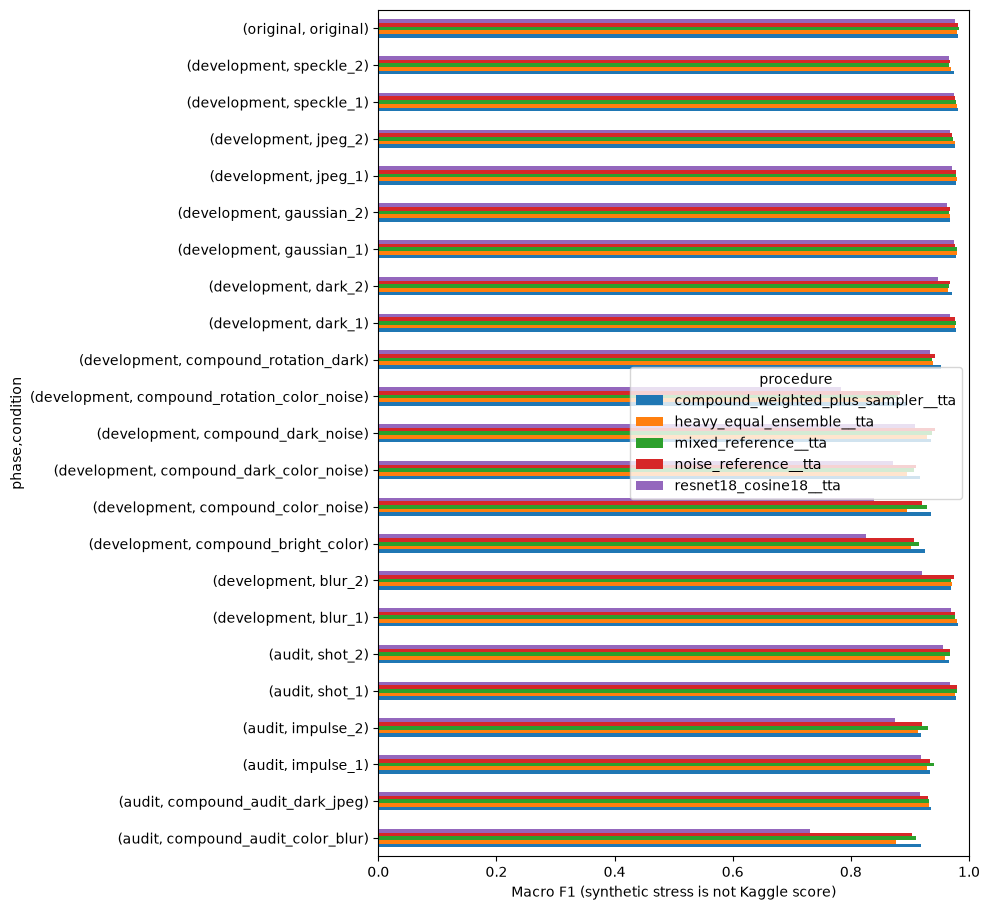

,F1_7-11k,F1_fiveN,F1_freefried,F1_pube,F1_roblock
procedure,,,,,
compound_weighted_plus_sampler__tta,0.989827,0.978644,0.988012,0.981497,0.966256
heavy_equal_ensemble__tta,0.989549,0.978536,0.987718,0.980593,0.965299
mixed_reference__tta,0.990178,0.980682,0.993750,0.982649,0.965300
noise_reference__tta,0.990572,0.980102,0.992864,0.983094,0.963722
resnet18_cosine18__tta,0.986330,0.974880,0.981732,0.975506,0.959106


Ready: False | Test access requires full mode + all gates + refit below


In [27]:
report=development_scores if audit_scores is None else pd.concat([development_scores,audit_scores],ignore_index=True)
display(report.groupby(['phase','procedure']).macro_F1.agg(['mean','min','max']))
pivot=report.pivot_table(index=['phase','condition'],columns='procedure',values='macro_F1')
ax=pivot.plot.barh(figsize=(10,max(4,len(pivot)*.4)))
ax.set(xlabel='Macro F1 (synthetic stress is not Kaggle score)',xlim=(0,1))
plt.tight_layout();plt.savefig(OUT/'robustness_comparison.png',dpi=120);plt.show()
display(report.loc[report.phase.eq('original')].groupby('procedure')[[c for c in report if c.startswith('F1_')]].mean())
print('Ready:',READY,'| Test access requires full mode + all gates + refit below')


## 8. Authorized full-data refit หลังประเมินครบ

หลัง CV ครบ5 folds และ final audit เสร็จ ฝึกบน Train ทั้งหมดอีก6 epochs จาก heavy_weighted18/full และเก็บ model.pt แม้ strict screening ยังไม่ผ่าน. การฝึกสำเร็จไม่เท่ากับผ่านเกณฑ์เลือกส่ง. Export ยังคงต้องผ่านทั้ง development และ audit.

In [28]:
full_path=None
if RUN_MODE=='full' and FULL_EVALUATED and RUN_FINAL_REFIT:
    full_path=training.fit_fixed(RAW,groups,training.RECIPES[RECIPE],OUT/RECIPE/'full',BATCH_SIZE,NUM_WORKERS,
        init_path=HEAVY/'heavy_weighted18/full/model.pt')
    print('Saved:',full_path,'| Strict evaluation passed:',READY)
    validation.write_json(OUT/'full_refit_status.json',{'model':str(full_path),'sha256':validation.sha(full_path),'strict_passed':READY,'authorized_experimental_refit':True})
else:print('No refit: ต้องประเมินครบ CV/audit และเปิด RUN_FINAL_REFIT')


full epoch 1 / 6 loss 0.07732 seconds 184.3
full epoch 2 / 6 loss 0.0726 seconds 200.6
full epoch 3 / 6 loss 0.06801 seconds 177.0
full epoch 4 / 6 loss 0.0592 seconds 175.7
full epoch 5 / 6 loss 0.05065 seconds 175.6
full epoch 6 / 6 loss 0.04565 seconds 175.5
Saved: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/compound_supervised_v1/compound_supervised6/full/model.pt | Strict evaluation passed: False


## 9. Frozen Test inference & combined submission

**เป็น cell แรกที่อ่าน Test** และอ่านไฟล์ submission เดิม. เปิดได้เฉพาะเมื่อ READY และ full checkpoint พร้อม. คง ID/Task1–3/Task5 จาก submission heavy_balance_v1; เปลี่ยนเฉพาะ Task4. Predictions ที่คล้ายไฟล์เดิมไม่ใช้เป็น selection metric. ไม่มีการส่ง Kaggle อัตโนมัติ.

In [29]:
if READY and RUN_EXPORT and full_path is not None:
    assert validation.sha(BASE_SUBMISSION)==BASE_SHA
    test=pd.read_csv(RAW/'test.csv')
    assert test.columns.tolist()==['id','file_name','label'] and test.label.isna().all()
    assert len(test)==25889 and test.id.is_unique and test.file_name.is_unique
    members=[]
    paths={'compound':full_path,'sampler':HEAVY/'heavy_sampler18/full/model.pt'}
    for member,path in paths.items():
        cache=OUT/f'{member}_test_tta.parquet';meta=cache.with_suffix('.json')
        signature={'model_sha256':validation.sha(path),'manifest_sha256':validation.sha(RAW/'test.csv'),'views':list(training.TTA_VIEWS),'source_hashes':source_hashes}
        if cache.exists():
            assert meta.exists() and json.loads(meta.read_text())==signature
            saved=pd.read_parquet(cache);assert saved.id.tolist()==test.id.tolist()
            p=saved[[f'p{i}' for i in range(5)]].to_numpy()
        else:
            model=training.load_model(path)
            pp=training.predict_views(model,RAW,test,'test',32,NUM_WORKERS)
            p=np.mean(list(pp.values()),axis=0)
            saved=pd.DataFrame(p,columns=[f'p{i}' for i in range(5)]);saved.insert(0,'id',test.id)
            temp=cache.with_suffix('.partial.parquet');saved.to_parquet(temp,index=False);temp.replace(cache)
            validation.write_json(meta,signature)
            del model;gc.collect()
            if training.get_device().type=='mps':torch.mps.empty_cache()
            if training.get_device().type=='cuda':torch.cuda.empty_cache()
        assert np.isfinite(p).all() and p.shape==(len(test),5) and np.allclose(p.sum(1),1,atol=1e-5)
        members.append(p)
    prediction=np.mean(members,axis=0).argmax(1)
    pd.DataFrame({'id':test.id,'task4':prediction}).to_parquet(OUT/'task4_predictions.parquet',index=False)
    with BASE_SUBMISSION.open(newline='') as f:source=list(csv.reader(f))
    assert source[0]==['id','task1','task2','task3','task4','task5']
    assert [r[0] for r in source[1:]]==test.id.tolist()
    rows=[r.copy() for r in source]
    for row,value in zip(rows[1:],prediction):row[4]=str(int(value))
    assert all(a[:4]+a[5:]==b[:4]+b[5:] for a,b in zip(source,rows))
    destination=ROOT/'submission'/f'kaggle_t12345_t4_{RUN_NAME}_t5_directional_gap_cut_v1.csv'
    if destination.exists():
        with destination.open(newline='') as f:assert list(csv.reader(f))==rows,'Refuse overwrite of different predictions'
    else:
        with destination.open('x',newline='') as f:csv.writer(f).writerows(rows)
    with destination.open(newline='') as f:assert list(csv.reader(f))==rows
    validation.write_json(destination.with_suffix('.json'),{'procedure':validation.NAME,'source':str(BASE_SUBMISSION),'source_sha256':BASE_SHA,
        'output_sha256':validation.sha(destination),'rows':len(test),'task5':'directional_gap_cut_v1','kaggle_submitted':False})
    print('Ready for user review:',destination)
else:print('ไม่ได้อ่าน Test หรือสร้าง submission: pilot/validation ยังไม่ผ่าน หรือปิด export')


ไม่ได้อ่าน Test หรือสร้าง submission: pilot/validation ยังไม่ผ่าน หรือปิด export


## 10. Resume / limitations / research

- Checkpoint ทุก epoch: model/optimizer/scheduler/scaler/RNG/history. Run All เดิมเพื่อ resume; epoch ที่ค้างจะเริ่มใหม่. แต่ละ stress condition ที่เสร็จมี cache. ห้ามเขียน run เดียวพร้อมกันสอง kernel.
- Pilot เพิ่ม 1 model ×6 epochs; full รวม5 models ×6 epochs และ full refit เพิ่ม6 epochs. แต่หนึ่ง batch มีเพียง1ภาพต่อ original; ไม่ได้ forward สาม views แบบรอบก่อน. Stress ต้อง inference สูงสุด6 models ×16 development conditions ×500 images ×5 TTA ต่อ fold; final audit เพิ่ม6 conditions. ไม่ได้เทรน baseline ใหม่.
- ใช้เฉพาะ Train ในการฝึก/เลือกสูตร. Fixed corruption strengths มาจาก protocol ของงานนี้ที่อิงกลุ่ม corruption ในวรรณกรรม ไม่ได้วัดหรือ fit จาก Test; ห้ามตีความว่าเป็น exact ImageNet-C implementation.
- สูตรก่อนหน้าเคยเลือกจาก OOF ชุดเดียวกัน; pilot และ full เป็น exploratory. Synthetic stress อาจไม่ตรง hidden Test. ผ่านเกณฑ์ช่วยประกอบการตัดสินใจ แต่ไม่รับประกันคะแนนหรือป้องกันเสีย submission ได้ทั้งหมด.
- [ImageNet-C evaluation concept](https://arxiv.org/abs/1903.12261). สูตรนี้เป็น supervised corruption fine-tuning ไม่ได้ใช้ AugMix หรือ JSD; validation protocol สืบต่อจาก notebook ก่อนหน้า.
